# NYC Taxi Trip Duration — Notebook
Predict the **duration (minutes)** of a New York City taxi trip from information known **before the trip ends**
(distance, pickup time, boroughs, passengers, taxi color).

Contents: 1) data loading & diagnostics, 2) cleaning / feature preparation, 3) EDA, 4) feature importance,
5) model selection & hyper-parameter tuning (Ridge, Decision Tree, Random Forest, XGBoost), 6) final model on the test set.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

plt.rcParams["figure.figsize"] = (7, 4)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

## 1. Load data & diagnostics

In [2]:
df = pd.read_csv("data/taxis.csv")
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print()
print(df.dtypes)
print()
print("Missing values per column:")
print(df.isnull().sum())
df.head()

Shape: (6433, 14)
Columns: ['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls', 'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']

pickup                 str
dropoff                str
passengers           int64
distance           float64
fare               float64
tip                float64
tolls              float64
total              float64
color                  str
payment                str
pickup_zone            str
dropoff_zone           str
pickup_borough         str
dropoff_borough        str
dtype: object

Missing values per column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [3]:
print(df.describe().T)
print()
for c in ["color", "payment", "pickup_borough", "dropoff_borough", "passengers"]:
    print(df[c].value_counts(dropna=False).to_string(), "\n")
print("Pickup range:", df["pickup"].min(), "->", df["pickup"].max())

             count       mean        std  min    25%    50%    75%     max
passengers  6433.0   1.539251   1.203768  0.0   1.00   1.00   2.00    6.00
distance    6433.0   3.024617   3.827867  0.0   0.98   1.64   3.21   36.70
fare        6433.0  13.091073  11.551804  1.0   6.50   9.50  15.00  150.00
tip         6433.0   1.979220   2.448560  0.0   0.00   1.70   2.80   33.20
tolls       6433.0   0.325273   1.415267  0.0   0.00   0.00   0.00   24.02
total       6433.0  18.517794  13.815570  1.3  10.80  14.16  20.30  174.82

color
yellow    5451
green      982 

payment
credit card    4577
cash           1812
NaN              44 

pickup_borough
Manhattan    5268
Queens        657
Brooklyn      383
Bronx          99
NaN            26 

dropoff_borough
Manhattan        5206
Queens            542
Brooklyn          501
Bronx             137
NaN                45
Staten Island       2 

passengers
1    4678
2     876
5     277
3     243
6     153
4     110
0      96 

Pickup range: 2019-02-28 2

## 2. Cleaning & feature preparation
* **Target** = `dropoff - pickup` in minutes.
* **Leakage:** `fare`, `tip`, `tolls`, `total`, `payment` are only known after the trip → **not used** as features.
* Drop impossible trips (zero distance, duration < 1 min or > 120 min).
* Missing boroughs → `"Unknown"`.
* New features: `pickup_hour`, `pickup_dayofweek`, `log_distance`.

In [4]:
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60

n0 = len(df)
bad = (df["distance"] <= 0) | (df["duration_min"] < 1) | (df["duration_min"] > 120)
print(f"Rows removed as invalid: {bad.sum()} of {n0} ({bad.mean():.1%})")
df = df[~bad].copy()

for c in ["pickup_borough", "dropoff_borough"]:
    df[c] = df[c].fillna("Unknown")

df["pickup_hour"] = df["pickup"].dt.hour
df["pickup_dayofweek"] = df["pickup"].dt.dayofweek          # 0 = Monday
df["log_distance"] = np.log1p(df["distance"])

NUM = ["distance", "log_distance", "passengers", "pickup_hour", "pickup_dayofweek"]
CAT = ["color", "pickup_borough", "dropoff_borough"]
FEATURES = NUM + CAT
TARGET = "duration_min"
print("Final shape:", df.shape)
df[FEATURES + [TARGET]].head()

Rows removed as invalid: 83 of 6433 (1.3%)
Final shape: (6350, 18)


,distance,log_distance,passengers,pickup_hour,pickup_dayofweek,color,pickup_borough,dropoff_borough,duration_min
0,1.60,0.955511,1,20,5,yellow,Manhattan,Manhattan,6.250000
1,0.79,0.582216,1,16,0,yellow,Manhattan,Manhattan,7.083333
2,1.37,0.862890,1,17,2,yellow,Manhattan,Manhattan,7.400000
3,7.70,2.163323,1,1,6,yellow,Manhattan,Manhattan,25.866667
4,2.16,1.150572,3,13,5,yellow,Manhattan,Manhattan,9.533333


## 3. Exploratory data analysis

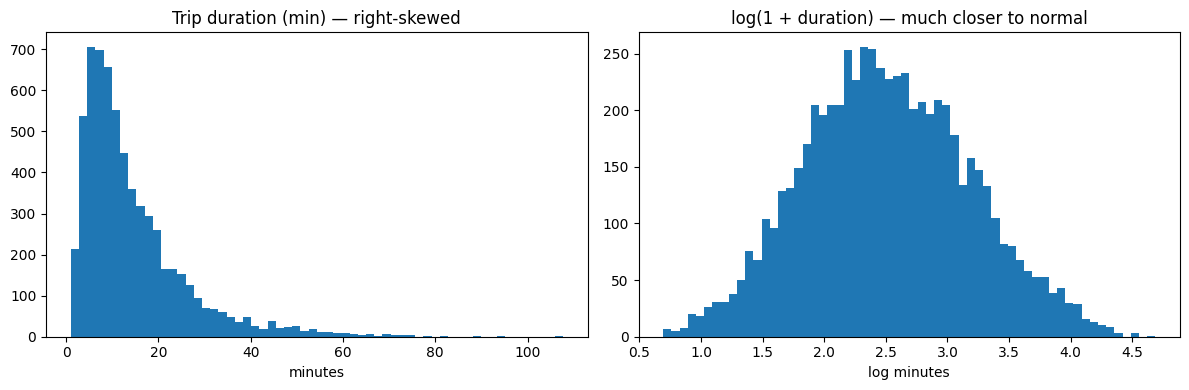

count    6350.000000
mean       14.514373
std        11.600687
min         1.000000
25%         6.654167
50%        11.000000
75%        18.600000
max       107.666667
Name: duration_min, dtype: float64
Skewness raw: 2.02 | log: 0.12


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df[TARGET], bins=60); ax[0].set_title("Trip duration (min) — right-skewed"); ax[0].set_xlabel("minutes")
ax[1].hist(np.log1p(df[TARGET]), bins=60); ax[1].set_title("log(1 + duration) — much closer to normal"); ax[1].set_xlabel("log minutes")
plt.tight_layout(); plt.show()
print(df[TARGET].describe())
print("Skewness raw:", round(df[TARGET].skew(), 2), "| log:", round(np.log1p(df[TARGET]).skew(), 2))

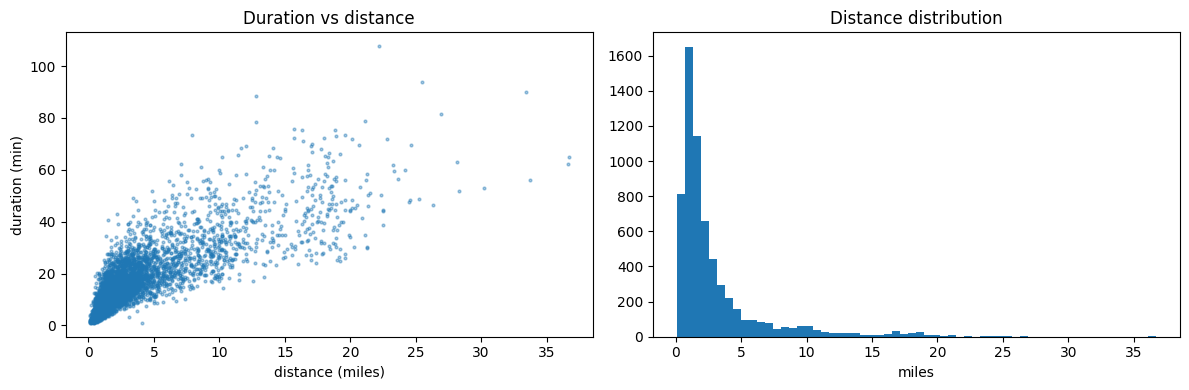

Correlation (numeric features vs target):
duration_min        1.000000
log_distance        0.851012
distance            0.823477
pickup_hour        -0.005064
passengers         -0.008473
pickup_dayofweek   -0.049938
Name: duration_min, dtype: float64


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(df["distance"], df[TARGET], s=4, alpha=0.4); ax[0].set_xlabel("distance (miles)"); ax[0].set_ylabel("duration (min)"); ax[0].set_title("Duration vs distance")
ax[1].hist(df["distance"], bins=60); ax[1].set_title("Distance distribution"); ax[1].set_xlabel("miles")
plt.tight_layout(); plt.show()
print("Correlation (numeric features vs target):")
print(df[NUM + [TARGET]].corr()[TARGET].sort_values(ascending=False))

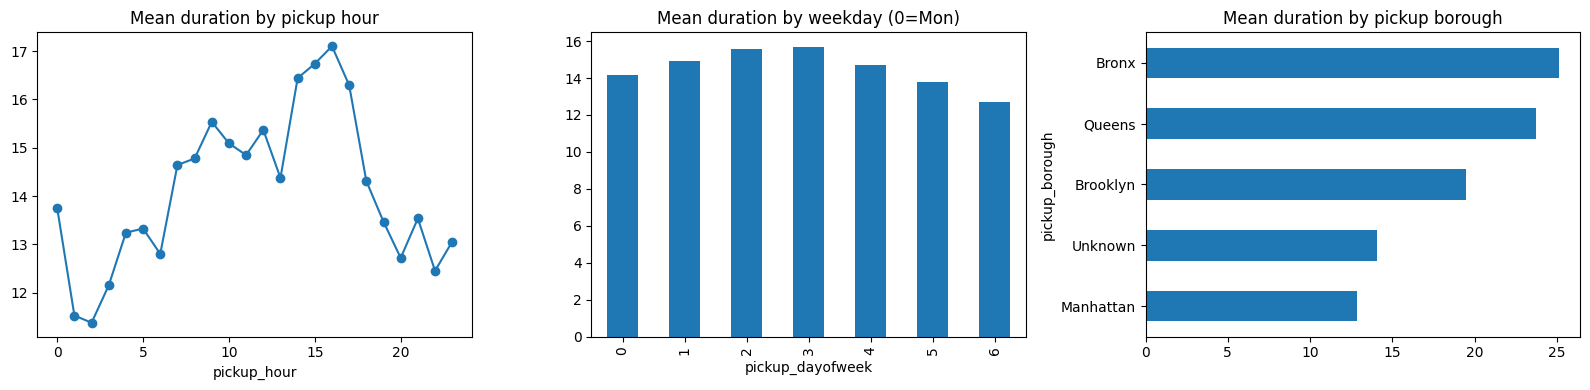

        count       mean     median
color                              
green     951  16.033386  11.216667
yellow   5399  14.246808  11.000000


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("pickup_hour")[TARGET].mean().plot(ax=ax[0], marker="o"); ax[0].set_title("Mean duration by pickup hour")
df.groupby("pickup_dayofweek")[TARGET].mean().plot(kind="bar", ax=ax[1]); ax[1].set_title("Mean duration by weekday (0=Mon)")
df.groupby("pickup_borough")[TARGET].mean().sort_values().plot(kind="barh", ax=ax[2]); ax[2].set_title("Mean duration by pickup borough")
plt.tight_layout(); plt.show()
print(df.groupby("color")[TARGET].agg(["count", "mean", "median"]))

## 4. Split + simple feature-importance analysis (mutual information)

3810 1270 1270


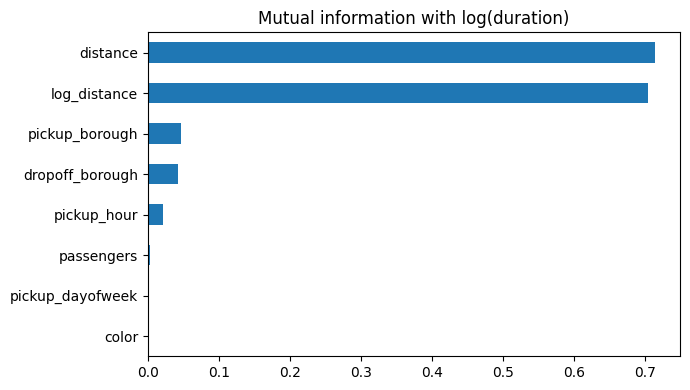

distance            0.714101
log_distance        0.704004
pickup_borough      0.046236
dropoff_borough     0.041869
pickup_hour         0.021211
passengers          0.002574
color               0.000000
pickup_dayofweek    0.000000
dtype: float64


In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
print(len(df_train), len(df_val), len(df_test))

y_train = np.log1p(df_train[TARGET].values)   # models are trained on log(1 + minutes)
y_val_min = df_val[TARGET].values              # metrics are computed in minutes

# Mutual information between each ORIGINAL feature and the (log) target, on the training set
X_mi = df_train[FEATURES].copy()
for c in CAT:
    X_mi[c] = X_mi[c].astype("category").cat.codes
mi = mutual_info_regression(X_mi, y_train, discrete_features=[f in CAT + ["passengers", "pickup_hour", "pickup_dayofweek"] for f in FEATURES], random_state=1)
mi = pd.Series(mi, index=FEATURES).sort_values()
mi.plot(kind="barh", title="Mutual information with log(duration)"); plt.tight_layout(); plt.show()
print(mi.sort_values(ascending=False))

## 5. Model selection & hyper-parameter tuning
Metric: **RMSE in minutes** on the validation set (also MAE and R²). Models are trained on `log(1 + duration)` and predictions are converted back with `expm1`.

In [9]:
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(df_train[FEATURES].to_dict(orient="records"))
X_val = dv.transform(df_val[FEATURES].to_dict(orient="records"))
feature_names = list(dv.get_feature_names_out())
print("Matrix:", X_train.shape)

def scores(model):
    pred = np.expm1(model.predict(X_val))
    return (np.sqrt(mean_squared_error(y_val_min, pred)),
            mean_absolute_error(y_val_min, pred),
            r2_score(y_val_min, pred))

results = []
def log(name, params, model):
    rmse, mae, r2 = scores(model)
    results.append({"model": name, "params": params, "val_rmse": rmse, "val_mae": mae, "val_r2": r2})

# --- baseline: always predict the training median
log("Baseline (median)", {}, DummyRegressor(strategy="median").fit(X_train, y_train))

# --- Linear: Ridge
for a in [0.01, 0.1, 1, 10, 100]:
    log("Ridge", {"alpha": a}, Ridge(alpha=a).fit(X_train, y_train))

# --- Decision tree
for d in [3, 5, 8, 12, 16]:
    log("DecisionTree", {"max_depth": d}, DecisionTreeRegressor(max_depth=d, min_samples_leaf=3, random_state=1).fit(X_train, y_train))

# --- Random forest
for d, n in itertools.product([8, 12, 20], [100, 300]):
    log("RandomForest", {"max_depth": d, "n_estimators": n},
        RandomForestRegressor(n_estimators=n, max_depth=d, min_samples_leaf=3, random_state=1, n_jobs=-1).fit(X_train, y_train))

# --- XGBoost
for lr, d, mcw in itertools.product([0.05, 0.1], [3, 4, 6], [1, 5]):
    log("XGBoost", {"learning_rate": lr, "max_depth": d, "min_child_weight": mcw},
        xgb.XGBRegressor(n_estimators=300, learning_rate=lr, max_depth=d, min_child_weight=mcw,
                         subsample=0.8, colsample_bytree=0.8, objective="reg:squarederror",
                         random_state=1, n_jobs=-1).fit(X_train, y_train))

res = pd.DataFrame(results).sort_values("val_rmse").reset_index(drop=True)
res[["model", "params", "val_rmse", "val_mae", "val_r2"]].round(4).head(15)

Matrix: (3810, 18)


,model,params,val_rmse,val_mae,val_r2
0,XGBoost,"{'learning_rate': 0.05, 'max_depth': 4, 'min_c...",5.1079,3.3405,0.8103
1,XGBoost,"{'learning_rate': 0.05, 'max_depth': 4, 'min_c...",5.1459,3.3456,0.8075
2,XGBoost,"{'learning_rate': 0.1, 'max_depth': 3, 'min_ch...",5.1517,3.3425,0.8070
3,XGBoost,"{'learning_rate': 0.05, 'max_depth': 3, 'min_c...",5.1981,3.3558,0.8036
4,XGBoost,"{'learning_rate': 0.1, 'max_depth': 4, 'min_ch...",5.2036,3.3621,0.8031
5,XGBoost,"{'learning_rate': 0.1, 'max_depth': 3, 'min_ch...",5.2036,3.3524,0.8031
6,XGBoost,"{'learning_rate': 0.1, 'max_depth': 4, 'min_ch...",5.2261,3.3692,0.8014
7,XGBoost,"{'learning_rate': 0.05, 'max_depth': 3, 'min_c...",5.2261,3.3700,0.8014
8,XGBoost,"{'learning_rate': 0.05, 'max_depth': 6, 'min_c...",5.2854,3.4091,0.7969
9,XGBoost,"{'learning_rate': 0.05, 'max_depth': 6, 'min_c...",5.3011,3.4035,0.7957


            model                                                         params  val_rmse  val_mae  val_r2
          XGBoost {'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 5}    5.1079   3.3405  0.8103
     RandomForest                          {'max_depth': 8, 'n_estimators': 100}    5.4194   3.4787  0.7865
     DecisionTree                                               {'max_depth': 5}    5.9887   3.8274  0.7393
            Ridge                                                 {'alpha': 100}    6.1095   4.0416  0.7286
Baseline (median)                                                             {}   12.2444   7.9840 -0.0900


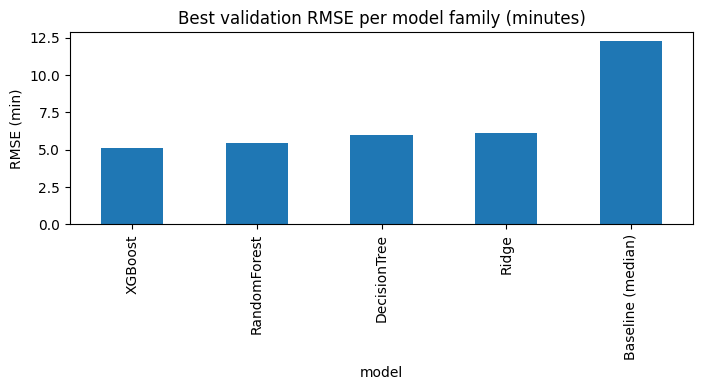

In [10]:
best_per_model = res.groupby("model", as_index=False).first().sort_values("val_rmse")
print(best_per_model[["model", "params", "val_rmse", "val_mae", "val_r2"]].round(4).to_string(index=False))
best_per_model.plot(x="model", y="val_rmse", kind="bar", legend=False, title="Best validation RMSE per model family (minutes)")
plt.ylabel("RMSE (min)"); plt.tight_layout(); plt.show()

## 6. Final model: retrain on train+validation, evaluate once on the test set

Best configuration: XGBoost {'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 5} (val RMSE = 5.108 min)


TEST  RMSE = 4.850 min | MAE = 3.235 min | R2 = 0.828
Baseline (median) TEST RMSE = 12.211 min


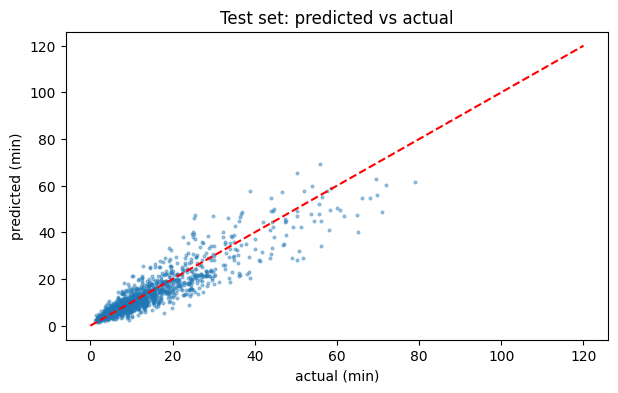

In [11]:
best = res.iloc[0]
print("Best configuration:", best["model"], best["params"], f"(val RMSE = {best['val_rmse']:.3f} min)")
assert best["model"] == "XGBoost"

BEST_PARAMS = best["params"]
final_dv = DictVectorizer(sparse=True)
X_ft = final_dv.fit_transform(df_full_train[FEATURES].to_dict(orient="records"))
X_te = final_dv.transform(df_test[FEATURES].to_dict(orient="records"))
final = xgb.XGBRegressor(n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                         objective="reg:squarederror", random_state=1, n_jobs=-1, **BEST_PARAMS)
final.fit(X_ft, np.log1p(df_full_train[TARGET].values))

pred_te = np.expm1(final.predict(X_te))
y_te = df_test[TARGET].values
print(f"TEST  RMSE = {np.sqrt(mean_squared_error(y_te, pred_te)):.3f} min | MAE = {mean_absolute_error(y_te, pred_te):.3f} min | R2 = {r2_score(y_te, pred_te):.3f}")
base_rmse = np.sqrt(mean_squared_error(y_te, np.full_like(y_te, df_full_train[TARGET].median())))
print(f"Baseline (median) TEST RMSE = {base_rmse:.3f} min")

plt.scatter(y_te, pred_te, s=4, alpha=0.4); plt.plot([0, 120], [0, 120], "r--")
plt.xlabel("actual (min)"); plt.ylabel("predicted (min)"); plt.title("Test set: predicted vs actual"); plt.show()

### Feature importance of the final model (permutation importance on the test set, per original feature)

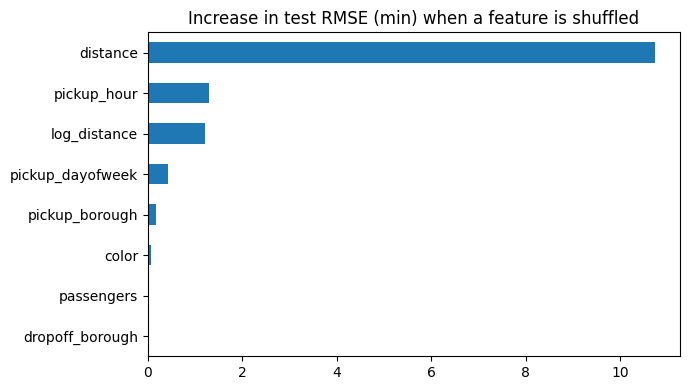

distance            10.730
pickup_hour          1.292
log_distance         1.199
pickup_dayofweek     0.428
pickup_borough       0.180
color                0.073
passengers           0.020
dropoff_borough      0.018
dtype: float64


In [12]:
def rmse_test(frame):
    X = final_dv.transform(frame[FEATURES].to_dict(orient="records"))
    return np.sqrt(mean_squared_error(y_te, np.expm1(final.predict(X))))

base = rmse_test(df_test)
rng = np.random.RandomState(1)
imp = {}
for f in FEATURES:
    drops = []
    for _ in range(5):
        shuffled = df_test.copy()
        shuffled[f] = rng.permutation(shuffled[f].values)
        if f == "distance":                      # keep the derived column consistent
            shuffled["log_distance"] = np.log1p(shuffled["distance"])
        drops.append(rmse_test(shuffled) - base)
    imp[f] = np.mean(drops)
imp = pd.Series(imp).sort_values()
imp.plot(kind="barh", title="Increase in test RMSE (min) when a feature is shuffled"); plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(3))

## Conclusions
* Duration is strongly right-skewed → training on `log(1 + duration)` helps all models.
* Distance dominates; pickup hour, weekday and borough add smaller but real signal.
* Tree ensembles beat the linear baseline, and **XGBoost** gives the lowest validation RMSE → selected for deployment.
* The final training logic is exported to `train.py`; the model is served by `predict.py` (FastAPI).